# Fine-tuning Time vs Performance: PEFT Methods on Llama 3.2 1B
**Task:** classify customer-support queries into 27 intents (Bitext dataset, ~27k rows, ~1k per intent).
**Model:** `meta-llama/Llama-3.2-1B-Instruct` (hardware-limited; larger Llama models would likely score higher).

**Methods compared (all with Hugging Face `transformers` + `peft`):**
zero-shot, few-shot, LoRA, QLoRA, IA3 (adapter-style), prompt tuning, prefix tuning. MPNet full fine-tune is included only as a small-encoder reference row.

**Measured per method:** training time, peak VRAM, trainable parameters, accuracy, macro-F1, 11-category accuracy, inference time, adapter size.

**Before you run (Kaggle):** GPU = T4, Internet = On, add a Secret named `HF_TOKEN`, and accept the Llama 3.2 license on Hugging Face.
First run once with `SMOKE_TEST = True` (a few minutes) to confirm every method works, then set it to `False`.

## 0. Install

In [23]:
!pip install -q -U transformers peft bitsandbytes accelerate datasets

In [24]:
# ============================================================
# FIX PEFT / TORCHAO COMPATIBILITY
# ============================================================

!pip install -q --upgrade "torchao>=0.16.0"

## 1. Imports

In [25]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import gc, json, re, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

import transformers, peft
from datasets import load_dataset, Dataset

from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    AutoModelForSequenceClassification,
    BitsAndBytesConfig,
    DataCollatorWithPadding,
    Trainer,
    TrainingArguments,
    set_seed,
)

from peft import (
    LoraConfig,
    IA3Config,
    PromptTuningConfig,
    PromptTuningInit,
    PrefixTuningConfig,
    TaskType,
    get_peft_model,
    prepare_model_for_kbit_training,
)

from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")

print(
    "torch", torch.__version__,
    "| transformers", transformers.__version__,
    "| peft", peft.__version__
)

if torch.cuda.is_available():
    print("CUDA: AVAILABLE")
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("CUDA: NOT AVAILABLE")

torch 2.11.0+cu128 | transformers 5.18.0 | peft 0.21.2
CUDA: AVAILABLE
GPU: Tesla T4


In [ ]:
# ---------------- CONFIG ----------------
SMOKE_TEST = False          # True = tiny run to verify everything works; set False for the real run
SEED = 42
MODEL_ID   = "meta-llama/Llama-3.2-1B-Instruct"   # ungated mirror if you lack access: "unsloth/Llama-3.2-1B-Instruct"
MPNET_ID   = "sentence-transformers/all-mpnet-base-v2"
DATASET_ID = "bitext/Bitext-customer-support-llm-chatbot-training-dataset"

MAX_LEN = 64               # queries are short; tokenizer stats are printed below
EPOCHS  = 3
BATCH   = 32
LLM_EVAL_N = None          # None = evaluate zero/few-shot on the full test set; or set e.g. 1000 to save time
FEWSHOT_PER_CLASS = 1      # 1 example per class -> 27 shots in the prompt

# learning rate per method (PEFT methods need different LRs; this is normal)
LR = {"mpnet_baseline": 5e-5, "lora": 2e-4, "qlora": 2e-4, "ia3": 3e-3,
      "prompt_tuning": 3e-2, "prefix_tuning": 1e-2}

OUT = Path("/kaggle/working"); (OUT / "adapters").mkdir(parents=True, exist_ok=True)
RESULTS_FILE = OUT / ("results_smoke.json" if SMOKE_TEST else "results.json")
set_seed(SEED)
print("Results file:", RESULTS_FILE)

# ---------------- HF login (needed for gated Llama) ----------------
HF_TOKEN = # your hf token

if HF_TOKEN:
    from huggingface_hub import login
    login(token=HF_TOKEN)
else:
    print("WARNING: no HF_TOKEN found. Add a Kaggle secret named HF_TOKEN, or use the ungated mirror in MODEL_ID.")

# ---------------- results store (lets you resume across sessions) ----------------
def load_results():
    return json.loads(RESULTS_FILE.read_text()) if RESULTS_FILE.exists() else {}

def save_result(name, d):
    r = load_results(); r[name] = d
    RESULTS_FILE.write_text(json.dumps(r, indent=2))

Results file: /kaggle/working/results.json


## 2. Data collection

In [27]:
raw = load_dataset(DATASET_ID, split="train")
df = raw.to_pandas()
print("Raw shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df[["instruction", "category", "intent"]].head())

Raw shape: (26872, 5)
Columns: ['flags', 'instruction', 'category', 'intent', 'response']


,instruction,category,intent
0,question about cancelling order {{Order Number}},ORDER,cancel_order
1,i have a question about cancelling oorder {{Or...,ORDER,cancel_order
2,i need help cancelling puchase {{Order Number}},ORDER,cancel_order
3,I need to cancel purchase {{Order Number}},ORDER,cancel_order
4,"I cannot afford this order, cancel purchase {{...",ORDER,cancel_order


## 3. Data preprocessing and cleaning

Rows: 26872 -> 24635 after cleaning
27 intents, 11 categories


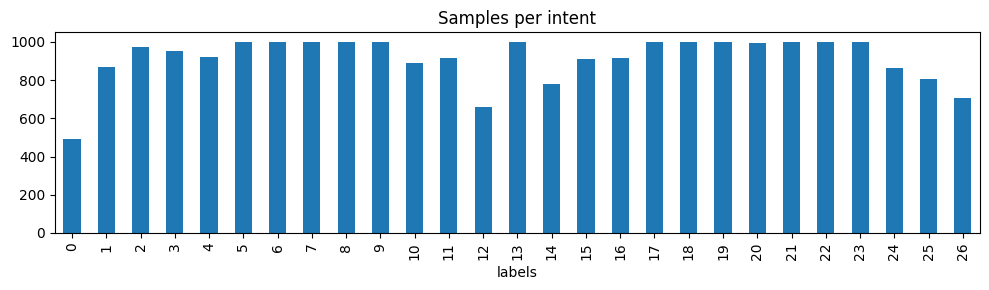

train/val/test: 19708 2463 2464 | epochs: 3


In [28]:
df = df[["instruction", "category", "intent"]].dropna().copy()
df["instruction"] = df["instruction"].astype(str).str.strip()
df = df[df["instruction"].str.len() > 0]
n0 = len(df)

# drop texts that appear with conflicting labels, then exact duplicates
conflict = df.groupby("instruction")["intent"].nunique()
df = df[~df["instruction"].isin(conflict[conflict > 1].index)]
df = df.drop_duplicates(subset="instruction").reset_index(drop=True)
print(f"Rows: {n0} -> {len(df)} after cleaning")

# label maps: 27 intents (training target) and the 11 categories (derived metric)
intents = sorted(df["intent"].unique())
label2id = {l: i for i, l in enumerate(intents)}
id2label = {i: l for l, i in label2id.items()}
NUM_LABELS = len(intents)
assert df.groupby("intent")["category"].nunique().max() == 1, "an intent maps to >1 category"
intent2cat = df.drop_duplicates("intent").set_index("intent")["category"].to_dict()
id2cat = {label2id[i]: intent2cat[i] for i in intents}
print(f"{NUM_LABELS} intents, {len(set(id2cat.values()))} categories")

df["labels"] = df["intent"].map(label2id)
df = df.rename(columns={"instruction": "text"})
df["labels"].value_counts().sort_index().plot(kind="bar", figsize=(10, 3), title="Samples per intent")
plt.tight_layout(); plt.show()

# stratified 80/10/10 split
train_df, temp_df = train_test_split(df, test_size=0.2, stratify=df["labels"], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.5, stratify=temp_df["labels"], random_state=SEED)

if SMOKE_TEST:
    EPOCHS = 1
    train_df = train_df.groupby("labels").head(20)
    val_df, test_df = val_df.head(270), test_df.head(270)

train_df, val_df, test_df = [d.reset_index(drop=True) for d in (train_df, val_df, test_df)]
print("train/val/test:", len(train_df), len(val_df), len(test_df), "| epochs:", EPOCHS)

## 4. Model selection
**Llama 3.2 1B Instruct** is the main model: small enough for a free Kaggle T4 with every PEFT method, and the Instruct version gives zero-shot/few-shot a fair chance.
All Llama methods share the same model, split, max length, batch size and epochs, so differences come from the method itself.
**MPNet (all-mpnet-base-v2)** is only a cheap full-fine-tune reference from a small encoder.

In [29]:
def make_tokenizer(model_id, padding_side):
    tok = AutoTokenizer.from_pretrained(model_id)
    tok.padding_side = padding_side
    if tok.pad_token is None:
        tok.pad_token = tok.eos_token
    return tok

# LEFT padding: the classification head then always reads the last real token
# (this also makes prompt tuning work, because it feeds embeddings instead of ids)
tok_llm = make_tokenizer(MODEL_ID, "left")

lens = np.array([len(x) for x in tok_llm(train_df["text"].tolist())["input_ids"]])
print("Token length p50/p90/p99/max:", np.percentile(lens, [50, 90, 99]).tolist(), lens.max())
print(f"Truncated at MAX_LEN={MAX_LEN}: {(lens > MAX_LEN).mean() * 100:.2f}%  (raise MAX_LEN if this is above ~1%)")

def tokenize_ds(df_, tok):
    ds_ = Dataset.from_pandas(df_[["text", "labels"]].reset_index(drop=True))
    return ds_.map(lambda b: tok(b["text"], truncation=True, max_length=MAX_LEN),
                   batched=True, remove_columns=["text"])

train_ds, val_ds, test_ds = [tokenize_ds(d, tok_llm) for d in (train_df, val_df, test_df)]

Token length p50/p90/p99/max: [11.0, 15.0, 18.0] 23
Truncated at MAX_LEN=64: 0.00%  (raise MAX_LEN if this is above ~1%)


Map:   0%|          | 0/19708 [00:00<?, ? examples/s]

Map:   0%|          | 0/2463 [00:00<?, ? examples/s]

Map:   0%|          | 0/2464 [00:00<?, ? examples/s]

## 5. Shared helpers: metrics, training args, timing logger

In [30]:
def compute_scores(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    cat_true = np.array([id2cat[int(i)] for i in y_true])
    cat_pred = np.array([id2cat.get(int(i), "UNK") for i in y_pred])
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_f1": float(f1_score(
            y_true, y_pred, average="macro",
            labels=list(range(NUM_LABELS)), zero_division=0
        )),
        "category_accuracy": float((cat_true == cat_pred).mean())
    }

def hf_metrics(eval_pred):
    logits, labels = eval_pred
    if isinstance(logits, tuple):
        logits = logits[0]
    preds = np.asarray(logits).argmax(-1)
    return {
        "accuracy": accuracy_score(labels, preds),
        "macro_f1": f1_score(labels, preds, average="macro", zero_division=0)
    }

def make_args(name, lr):
    return TrainingArguments(
        output_dir=str(OUT / "checkpoints" / name),
        num_train_epochs=EPOCHS,
        per_device_train_batch_size=BATCH,
        per_device_eval_batch_size=64,
        learning_rate=lr,
        weight_decay=0.0,
        lr_scheduler_type="linear",
        warmup_steps=10,
        logging_steps=10,
        save_strategy="epoch",
        save_total_limit=1,
        report_to="none",
        fp16=True,
        optim="adamw_torch",
        dataloader_num_workers=2,
        remove_unused_columns=False,
        label_names=["labels"],
        seed=SEED
    )

def count_params(model):
    if hasattr(model, "get_nb_trainable_parameters"):
        return model.get_nb_trainable_parameters()
    return (
        sum(p.numel() for p in model.parameters() if p.requires_grad),
        sum(p.numel() for p in model.parameters())
    )

def cast_trainable_fp32(model):
    for p in model.parameters():
        if p.requires_grad:
            p.data = p.data.float()

def cleanup():
    gc.collect()
    torch.cuda.empty_cache()

def dir_size_mb(path):
    path = Path(path)
    return sum(f.stat().st_size for f in path.rglob("*") if f.is_file()) / 1e6

def save_tokenizer(tok, path):
    Path(path).mkdir(parents=True, exist_ok=True)
    tok.save_pretrained(path)

print("Training helpers loaded. Each experiment below contains its own explicit trainer.train() call.")


Training helpers loaded. Each experiment below contains its own explicit trainer.train() call.


## 6. Zero-shot and few-shot (inference only, no training)

In [31]:
SYSTEM = ("You are a customer-support ticket classifier. Reply with exactly one label from the allowed list "
          "and nothing else.")
LABELS_TXT = "\n".join(intents)

def build_messages(query, shots=None):
    msgs = [{"role": "system", "content": SYSTEM + "\n\nAllowed labels:\n" + LABELS_TXT}]
    for q, l in (shots or []):
        msgs += [{"role": "user", "content": q}, {"role": "assistant", "content": l}]
    msgs.append({"role": "user", "content": query})
    return msgs

def parse_label(text):
    t = re.sub(r"[^a-z_ ]", "", text.strip().lower()).replace(" ", "_")
    if t in label2id: return label2id[t]
    hits = [l for l in intents if l in t]
    return label2id[max(hits, key=len)] if hits else -1      # -1 = unparseable (counted wrong)

@torch.no_grad()
def run_generative_eval(name, shots=None, batch_size=32):
    if name in load_results():
        print(f"[{name}] already done, skipping"); return
    print(f"\n===== {name} =====")
    cleanup(); torch.cuda.reset_peak_memory_stats()
    model = AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype=torch.float16).to("cuda").eval()
    ev = test_df if LLM_EVAL_N is None else test_df.sample(min(LLM_EVAL_N, len(test_df)), random_state=SEED)
    prompts = [tok_llm.apply_chat_template(build_messages(t, shots), tokenize=False, add_generation_prompt=True)
               for t in ev["text"]]
    preds, raws = [], []
    torch.cuda.synchronize(); t0 = time.time()
    for i in range(0, len(prompts), batch_size):
        enc = tok_llm(prompts[i:i + batch_size], return_tensors="pt", padding=True, add_special_tokens=False).to("cuda")
        out = model.generate(**enc, max_new_tokens=16, do_sample=False, temperature=None, top_p=None,
                             pad_token_id=tok_llm.pad_token_id)
        texts = tok_llm.batch_decode(out[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
        raws += texts; preds += [parse_label(t) for t in texts]
    torch.cuda.synchronize(); infer_time = time.time() - t0
    scores = compute_scores(ev["labels"].values, preds)
    res = {"method": name, "status": "ok", "trainable_params": 0, "total_params": int(sum(p.numel() for p in model.parameters())),
           "trainable_pct": 0.0, "train_time_min": 0.0, "time_per_epoch_min": 0.0,
           "peak_vram_gb": torch.cuda.max_memory_allocated() / 1e9, "test_inference_sec": infer_time,
           "ms_per_sample": 1000 * infer_time / len(ev), "val_accuracy": None, "adapter_size_mb": None,
           "unparsed_rate": float(np.mean(np.array(preds) == -1)), "loss_history": [], **scores}
    save_result(name, res)
    print(f"[{name}] acc {res['accuracy']:.4f} | macro-F1 {res['macro_f1']:.4f} | unparsed {res['unparsed_rate']:.1%} | "
          f"{res['ms_per_sample']:.0f} ms/sample")
    print("Sample raw outputs:", raws[:3])
    del model; cleanup()

run_generative_eval("zero_shot", shots=None, batch_size=32)


===== zero_shot =====


Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

[zero_shot] acc 0.1607 | macro-F1 0.1571 | unparsed 10.6% | 34 ms/sample
Sample raw outputs: ['change_shipping_address', 'cancel_order', 'complaint']


In [32]:
shots_df = (train_df.groupby("labels", group_keys=False)
            .apply(lambda g: g.sample(FEWSHOT_PER_CLASS, random_state=SEED))
            .sample(frac=1, random_state=SEED))
shots = [(r.text, id2label[r.labels]) for r in shots_df.itertuples()]
print(f"{len(shots)} few-shot examples")
run_generative_eval("few_shot", shots=shots, batch_size=16)

27 few-shot examples

===== few_shot =====


Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

[few_shot] acc 0.5755 | macro-F1 0.5629 | unparsed 3.6% | 131 ms/sample
Sample raw outputs: ['check_payment_methods', 'get_invoice', 'payment_issue']


## 7. Parameter-efficient fine-tuning on Llama 3.2 1B

Each method below is intentionally written as a **separate, visible training block**. Every block creates a fresh model, prints trainable parameters, calls `trainer.train()`, evaluates on validation/test data, and saves the trained adapter/model to `/kaggle/working/models/`.


In [33]:
def load_cls_model(quant=False):
    kw = dict(
        num_labels=NUM_LABELS,
        id2label=id2label,
        label2id=label2id,
        torch_dtype=torch.float16
    )

    if quant:
        bnb = BitsAndBytesConfig(
            load_in_4bit=True,
            bnb_4bit_quant_type="nf4",
            bnb_4bit_use_double_quant=True,
            bnb_4bit_compute_dtype=torch.float16,
            llm_int8_skip_modules=["score"]
        )
        model = AutoModelForSequenceClassification.from_pretrained(
            MODEL_ID,
            quantization_config=bnb,
            device_map={"": 0},
            **kw
        )
    else:
        model = AutoModelForSequenceClassification.from_pretrained(
            MODEL_ID, **kw
        ).to("cuda")

    model.config.pad_token_id = tok_llm.pad_token_id
    model.config.use_cache = False
    return model

print("Base classification model loader ready.")


Base classification model loader ready.


### 7a. LoRA — explicit training


In [34]:
# ============================================================
# LORA — EXPLICIT FINE-TUNING BLOCK
# ============================================================

name = "lora"
print("\n" + "=" * 70)
print("STARTING LORA FINE-TUNING")
print("=" * 70)
SKIP_COMPLETED=False
if SKIP_COMPLETED and name in load_results():
    print(f"[{name}] already completed; SKIP_COMPLETED=True so this block is skipped.")
else:
    set_seed(SEED)
    cleanup()
    torch.cuda.reset_peak_memory_stats()

    # 1. Fresh base model
    quant = False
    model = load_cls_model(quant=quant)

    # 2. Configure this PEFT method
    peft_config = LoraConfig(task_type=TaskType.SEQ_CLS, r=16, lora_alpha=32, lora_dropout=0.05, target_modules=["q_proj", "k_proj", "v_proj", "o_proj"])
    model = get_peft_model(model, peft_config)

    # 3. Show exactly what will be trained
    trainable, total = count_params(model)
    model.print_trainable_parameters()
    print(f"Trainable parameters: {trainable:,} / {total:,}")
    print(f"Trainable percentage: {100 * trainable / total:.4f}%")

    cast_trainable_fp32(model)

    # 4. EXPLICIT TRAINING OBJECT
    trainer = Trainer(
        model=model,
        args=make_args(name, LR[name]),
        train_dataset=train_ds,
        eval_dataset=val_ds,
        data_collator=DataCollatorWithPadding(tok_llm),
        compute_metrics=hf_metrics
    )

    print("\n>>> CALLING trainer.train() — THIS IS THE ACTUAL FINE-TUNING STEP <<<")
    torch.cuda.synchronize()
    t0 = time.time()
    train_output = trainer.train()
    torch.cuda.synchronize()
    train_time = time.time() - t0

    print(f">>> TRAINING FINISHED: {train_time/60:.2f} minutes")
    print(f">>> Final training loss: {train_output.training_loss:.6f}")

    # 5. Validation + test evaluation
    val_metrics = trainer.evaluate(eval_dataset=val_ds)

    torch.cuda.synchronize()
    t1 = time.time()
    pred = trainer.predict(test_ds)
    torch.cuda.synchronize()
    infer_time = time.time() - t1

    logits = pred.predictions[0] if isinstance(pred.predictions, tuple) else pred.predictions
    test_scores = compute_scores(pred.label_ids, np.asarray(logits).argmax(-1))

    # 6. SAVE THE TRAINED PEFT ADAPTER
    save_path = Path("/kaggle/working/models/lora")
    save_path.mkdir(parents=True, exist_ok=True)
    model.save_pretrained(save_path)
    save_tokenizer(tok_llm, save_path)

    # Also keep the final Trainer checkpoint files under /kaggle/working/checkpoints/
    print(f">>> ADAPTER SAVED TO: {save_path}")

    res = {
        "method": name,
        "status": "ok",
        "trainable_params": int(trainable),
        "total_params": int(total),
        "trainable_pct": 100 * trainable / total,
        "train_time_min": train_time / 60,
        "time_per_epoch_min": train_time / 60 / EPOCHS,
        "peak_vram_gb": torch.cuda.max_memory_allocated() / 1e9,
        "test_inference_sec": infer_time,
        "ms_per_sample": 1000 * infer_time / len(test_ds),
        "val_accuracy": float(val_metrics["eval_accuracy"]),
        "adapter_size_mb": dir_size_mb(save_path),
        "loss_history": [
            (x["step"], x["loss"])
            for x in trainer.state.log_history if "loss" in x
        ],
        **test_scores
    }
    save_result(name, res)

    print("\nRESULT")
    print(f"Test accuracy : {res['accuracy']:.4f}")
    print(f"Test macro-F1 : {res['macro_f1']:.4f}")
    print(f"Train time    : {res['train_time_min']:.2f} min")
    print(f"Peak VRAM     : {res['peak_vram_gb']:.2f} GB")

    del trainer, model
    cleanup()



STARTING LORA FINE-TUNING


Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

[transformers] LlamaForSequenceClassification LOAD REPORT from: meta-llama/Llama-3.2-1B-Instruct
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainable params: 3,463,168 || all params: 1,239,332,864 || trainable%: 0.2794
Trainable parameters: 3,463,168 / 1,239,332,864
Trainable percentage: 0.2794%

>>> CALLING trainer.train() — THIS IS THE ACTUAL FINE-TUNING STEP <<<


Step,Training Loss
10,4.066507
20,2.712070
30,1.254760
40,0.590928
50,0.414518
60,0.209864
70,0.102828
80,0.148574
90,0.044605
100,0.099963


>>> TRAINING FINISHED: 5.97 minutes
>>> Final training loss: 0.056648


Training Loss,Validation Loss,Step,Accuracy,Macro F1
0.000004,0.001964,1848,0.999188,0.999238


>>> ADAPTER SAVED TO: /kaggle/working/models/lora

RESULT
Test accuracy : 0.9992
Test macro-F1 : 0.9991
Train time    : 5.97 min
Peak VRAM     : 6.34 GB


### 7b. QLoRA — explicit training


In [35]:
# ============================================================
# QLORA — EXPLICIT FINE-TUNING BLOCK
# ============================================================

name = "qlora"
print("\n" + "=" * 70)
print("STARTING QLORA FINE-TUNING")
print("=" * 70)
SKIP_COMPLETED=False
if SKIP_COMPLETED and name in load_results():
    print(f"[{name}] already completed; SKIP_COMPLETED=True so this block is skipped.")
else:
    set_seed(SEED)
    cleanup()
    torch.cuda.reset_peak_memory_stats()

    # 1. Fresh base model
    quant = True
    model = load_cls_model(quant=quant)

    # 2. Configure this PEFT method
    peft_config = LoraConfig(task_type=TaskType.SEQ_CLS, r=16, lora_alpha=32, lora_dropout=0.05, target_modules=["q_proj", "k_proj", "v_proj", "o_proj"])
    model = get_peft_model(model, peft_config)

    # 3. Show exactly what will be trained
    trainable, total = count_params(model)
    model.print_trainable_parameters()
    print(f"Trainable parameters: {trainable:,} / {total:,}")
    print(f"Trainable percentage: {100 * trainable / total:.4f}%")

    cast_trainable_fp32(model)

    # 4. EXPLICIT TRAINING OBJECT
    trainer = Trainer(
        model=model,
        args=make_args(name, LR[name]),
        train_dataset=train_ds,
        eval_dataset=val_ds,
        data_collator=DataCollatorWithPadding(tok_llm),
        compute_metrics=hf_metrics
    )

    print("\n>>> CALLING trainer.train() — THIS IS THE ACTUAL FINE-TUNING STEP <<<")
    torch.cuda.synchronize()
    t0 = time.time()
    train_output = trainer.train()
    torch.cuda.synchronize()
    train_time = time.time() - t0

    print(f">>> TRAINING FINISHED: {train_time/60:.2f} minutes")
    print(f">>> Final training loss: {train_output.training_loss:.6f}")

    # 5. Validation + test evaluation
    val_metrics = trainer.evaluate(eval_dataset=val_ds)

    torch.cuda.synchronize()
    t1 = time.time()
    pred = trainer.predict(test_ds)
    torch.cuda.synchronize()
    infer_time = time.time() - t1

    logits = pred.predictions[0] if isinstance(pred.predictions, tuple) else pred.predictions
    test_scores = compute_scores(pred.label_ids, np.asarray(logits).argmax(-1))

    # 6. SAVE THE TRAINED PEFT ADAPTER
    save_path = Path("/kaggle/working/models/qlora")
    save_path.mkdir(parents=True, exist_ok=True)
    model.save_pretrained(save_path)
    save_tokenizer(tok_llm, save_path)

    # Also keep the final Trainer checkpoint files under /kaggle/working/checkpoints/
    print(f">>> ADAPTER SAVED TO: {save_path}")

    res = {
        "method": name,
        "status": "ok",
        "trainable_params": int(trainable),
        "total_params": int(total),
        "trainable_pct": 100 * trainable / total,
        "train_time_min": train_time / 60,
        "time_per_epoch_min": train_time / 60 / EPOCHS,
        "peak_vram_gb": torch.cuda.max_memory_allocated() / 1e9,
        "test_inference_sec": infer_time,
        "ms_per_sample": 1000 * infer_time / len(test_ds),
        "val_accuracy": float(val_metrics["eval_accuracy"]),
        "adapter_size_mb": dir_size_mb(save_path),
        "loss_history": [
            (x["step"], x["loss"])
            for x in trainer.state.log_history if "loss" in x
        ],
        **test_scores
    }
    save_result(name, res)

    print("\nRESULT")
    print(f"Test accuracy : {res['accuracy']:.4f}")
    print(f"Test macro-F1 : {res['macro_f1']:.4f}")
    print(f"Train time    : {res['train_time_min']:.2f} min")
    print(f"Peak VRAM     : {res['peak_vram_gb']:.2f} GB")

    del trainer, model
    cleanup()



STARTING QLORA FINE-TUNING


Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

[transformers] LlamaForSequenceClassification LOAD REPORT from: meta-llama/Llama-3.2-1B-Instruct
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainable params: 3,463,168 || all params: 1,239,332,864 || trainable%: 0.2794
Trainable parameters: 3,463,168 / 1,239,332,864
Trainable percentage: 0.2794%

>>> CALLING trainer.train() — THIS IS THE ACTUAL FINE-TUNING STEP <<<


Step,Training Loss
10,5.144551
20,2.981038
30,1.767279
40,0.555477
50,0.329497
60,0.258193
70,0.136927
80,0.145015
90,0.101416
100,0.041033


>>> TRAINING FINISHED: 6.99 minutes
>>> Final training loss: 0.068563


Training Loss,Validation Loss,Step,Accuracy,Macro F1
0.000007,0.000695,1848,0.999594,0.999606


>>> ADAPTER SAVED TO: /kaggle/working/models/qlora

RESULT
Test accuracy : 0.9984
Test macro-F1 : 0.9981
Train time    : 6.99 min
Peak VRAM     : 4.90 GB


### 7c. IA3 — explicit training


In [36]:
# ============================================================
# IA3 — EXPLICIT FINE-TUNING BLOCK
# ============================================================

name = "ia3"
print("\n" + "=" * 70)
print("STARTING IA3 FINE-TUNING")
print("=" * 70)
SKIP_COMPLETED=False
if SKIP_COMPLETED and name in load_results():
    print(f"[{name}] already completed; SKIP_COMPLETED=True so this block is skipped.")
else:
    set_seed(SEED)
    cleanup()
    torch.cuda.reset_peak_memory_stats()

    # 1. Fresh base model
    quant = False
    model = load_cls_model(quant=quant)

    # 2. Configure this PEFT method
    peft_config = IA3Config(task_type=TaskType.SEQ_CLS, target_modules=["k_proj", "v_proj", "down_proj"], feedforward_modules=["down_proj"])
    model = get_peft_model(model, peft_config)

    # 3. Show exactly what will be trained
    trainable, total = count_params(model)
    model.print_trainable_parameters()
    print(f"Trainable parameters: {trainable:,} / {total:,}")
    print(f"Trainable percentage: {100 * trainable / total:.4f}%")

    cast_trainable_fp32(model)

    # 4. EXPLICIT TRAINING OBJECT
    trainer = Trainer(
        model=model,
        args=make_args(name, LR[name]),
        train_dataset=train_ds,
        eval_dataset=val_ds,
        data_collator=DataCollatorWithPadding(tok_llm),
        compute_metrics=hf_metrics
    )

    print("\n>>> CALLING trainer.train() — THIS IS THE ACTUAL FINE-TUNING STEP <<<")
    torch.cuda.synchronize()
    t0 = time.time()
    train_output = trainer.train()
    torch.cuda.synchronize()
    train_time = time.time() - t0

    print(f">>> TRAINING FINISHED: {train_time/60:.2f} minutes")
    print(f">>> Final training loss: {train_output.training_loss:.6f}")

    # 5. Validation + test evaluation
    val_metrics = trainer.evaluate(eval_dataset=val_ds)

    torch.cuda.synchronize()
    t1 = time.time()
    pred = trainer.predict(test_ds)
    torch.cuda.synchronize()
    infer_time = time.time() - t1

    logits = pred.predictions[0] if isinstance(pred.predictions, tuple) else pred.predictions
    test_scores = compute_scores(pred.label_ids, np.asarray(logits).argmax(-1))

    # 6. SAVE THE TRAINED PEFT ADAPTER
    save_path = Path("/kaggle/working/models/ia3")
    save_path.mkdir(parents=True, exist_ok=True)
    model.save_pretrained(save_path)
    save_tokenizer(tok_llm, save_path)

    # Also keep the final Trainer checkpoint files under /kaggle/working/checkpoints/
    print(f">>> ADAPTER SAVED TO: {save_path}")

    res = {
        "method": name,
        "status": "ok",
        "trainable_params": int(trainable),
        "total_params": int(total),
        "trainable_pct": 100 * trainable / total,
        "train_time_min": train_time / 60,
        "time_per_epoch_min": train_time / 60 / EPOCHS,
        "peak_vram_gb": torch.cuda.max_memory_allocated() / 1e9,
        "test_inference_sec": infer_time,
        "ms_per_sample": 1000 * infer_time / len(test_ds),
        "val_accuracy": float(val_metrics["eval_accuracy"]),
        "adapter_size_mb": dir_size_mb(save_path),
        "loss_history": [
            (x["step"], x["loss"])
            for x in trainer.state.log_history if "loss" in x
        ],
        **test_scores
    }
    save_result(name, res)

    print("\nRESULT")
    print(f"Test accuracy : {res['accuracy']:.4f}")
    print(f"Test macro-F1 : {res['macro_f1']:.4f}")
    print(f"Train time    : {res['train_time_min']:.2f} min")
    print(f"Peak VRAM     : {res['peak_vram_gb']:.2f} GB")

    del trainer, model
    cleanup()



STARTING IA3 FINE-TUNING


Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

[transformers] LlamaForSequenceClassification LOAD REPORT from: meta-llama/Llama-3.2-1B-Instruct
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainable params: 202,752 || all params: 1,236,072,448 || trainable%: 0.0164
Trainable parameters: 202,752 / 1,236,072,448
Trainable percentage: 0.0164%

>>> CALLING trainer.train() — THIS IS THE ACTUAL FINE-TUNING STEP <<<


Step,Training Loss
10,3.701695
20,1.471415
30,1.228410
40,0.592420
50,0.800968
60,0.791803
70,0.408456
80,0.597606
90,0.365509
100,0.133011


>>> TRAINING FINISHED: 5.48 minutes
>>> Final training loss: 0.091149


Training Loss,Validation Loss,Step,Accuracy,Macro F1
0.000000,0.021996,1848,0.998376,0.998435


>>> ADAPTER SAVED TO: /kaggle/working/models/ia3

RESULT
Test accuracy : 0.9992
Test macro-F1 : 0.9992
Train time    : 5.48 min
Peak VRAM     : 6.46 GB


### 7d. Prompt tuning — explicit training


In [37]:
# ============================================================
# PROMPT_TUNING — EXPLICIT FINE-TUNING BLOCK
# ============================================================

name = "prompt_tuning"
print("\n" + "=" * 70)
print("STARTING PROMPT_TUNING FINE-TUNING")
print("=" * 70)
SKIP_COMPLETED=False
if SKIP_COMPLETED and name in load_results():
    print(f"[{name}] already completed; SKIP_COMPLETED=True so this block is skipped.")
else:
    set_seed(SEED)
    cleanup()
    torch.cuda.reset_peak_memory_stats()

    # 1. Fresh base model
    quant = False
    model = load_cls_model(quant=quant)

    # 2. Configure this PEFT method
    peft_config = PromptTuningConfig(task_type=TaskType.SEQ_CLS, num_virtual_tokens=20, prompt_tuning_init=PromptTuningInit.TEXT, prompt_tuning_init_text="Classify this customer support query into the correct intent:", tokenizer_name_or_path=MODEL_ID)
    model = get_peft_model(model, peft_config)

    # 3. Show exactly what will be trained
    trainable, total = count_params(model)
    model.print_trainable_parameters()
    print(f"Trainable parameters: {trainable:,} / {total:,}")
    print(f"Trainable percentage: {100 * trainable / total:.4f}%")

    cast_trainable_fp32(model)

    # 4. EXPLICIT TRAINING OBJECT
    trainer = Trainer(
        model=model,
        args=make_args(name, LR[name]),
        train_dataset=train_ds,
        eval_dataset=val_ds,
        data_collator=DataCollatorWithPadding(tok_llm),
        compute_metrics=hf_metrics
    )

    print("\n>>> CALLING trainer.train() — THIS IS THE ACTUAL FINE-TUNING STEP <<<")
    torch.cuda.synchronize()
    t0 = time.time()
    train_output = trainer.train()
    torch.cuda.synchronize()
    train_time = time.time() - t0

    print(f">>> TRAINING FINISHED: {train_time/60:.2f} minutes")
    print(f">>> Final training loss: {train_output.training_loss:.6f}")

    # 5. Validation + test evaluation
    val_metrics = trainer.evaluate(eval_dataset=val_ds)

    torch.cuda.synchronize()
    t1 = time.time()
    pred = trainer.predict(test_ds)
    torch.cuda.synchronize()
    infer_time = time.time() - t1

    logits = pred.predictions[0] if isinstance(pred.predictions, tuple) else pred.predictions
    test_scores = compute_scores(pred.label_ids, np.asarray(logits).argmax(-1))

    # 6. SAVE THE TRAINED PEFT ADAPTER
    save_path = Path("/kaggle/working/models/prompt_tuning")
    save_path.mkdir(parents=True, exist_ok=True)
    model.save_pretrained(save_path)
    save_tokenizer(tok_llm, save_path)

    # Also keep the final Trainer checkpoint files under /kaggle/working/checkpoints/
    print(f">>> ADAPTER SAVED TO: {save_path}")

    res = {
        "method": name,
        "status": "ok",
        "trainable_params": int(trainable),
        "total_params": int(total),
        "trainable_pct": 100 * trainable / total,
        "train_time_min": train_time / 60,
        "time_per_epoch_min": train_time / 60 / EPOCHS,
        "peak_vram_gb": torch.cuda.max_memory_allocated() / 1e9,
        "test_inference_sec": infer_time,
        "ms_per_sample": 1000 * infer_time / len(test_ds),
        "val_accuracy": float(val_metrics["eval_accuracy"]),
        "adapter_size_mb": dir_size_mb(save_path),
        "loss_history": [
            (x["step"], x["loss"])
            for x in trainer.state.log_history if "loss" in x
        ],
        **test_scores
    }
    save_result(name, res)

    print("\nRESULT")
    print(f"Test accuracy : {res['accuracy']:.4f}")
    print(f"Test macro-F1 : {res['macro_f1']:.4f}")
    print(f"Train time    : {res['train_time_min']:.2f} min")
    print(f"Peak VRAM     : {res['peak_vram_gb']:.2f} GB")

    del trainer, model
    cleanup()



STARTING PROMPT_TUNING FINE-TUNING


Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

[transformers] LlamaForSequenceClassification LOAD REPORT from: meta-llama/Llama-3.2-1B-Instruct
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainable params: 96,256 || all params: 1,235,965,952 || trainable%: 0.0078
Trainable parameters: 96,256 / 1,235,965,952
Trainable percentage: 0.0078%

>>> CALLING trainer.train() — THIS IS THE ACTUAL FINE-TUNING STEP <<<


Step,Training Loss
10,7.427847
20,11.877467
30,37.811862
40,25.541359
50,14.941159
60,9.006094
70,7.272684
80,6.014294
90,5.439467
100,5.668816


>>> TRAINING FINISHED: 10.34 minutes
>>> Final training loss: 4.049086


Training Loss,Validation Loss,Step,Accuracy,Macro F1
2.039368,1.886960,1848,0.439708,0.406285


>>> ADAPTER SAVED TO: /kaggle/working/models/prompt_tuning

RESULT
Test accuracy : 0.4403
Test macro-F1 : 0.4062
Train time    : 10.34 min
Peak VRAM     : 6.88 GB


### 7e. Prefix tuning — explicit training


In [38]:
# ============================================================
# PREFIX_TUNING — EXPLICIT FINE-TUNING BLOCK
# ============================================================

name = "prefix_tuning"
print("\n" + "=" * 70)
print("STARTING PREFIX_TUNING FINE-TUNING")
print("=" * 70)
SKIP_COMPLETED=False
if SKIP_COMPLETED and name in load_results():
    print(f"[{name}] already completed; SKIP_COMPLETED=True so this block is skipped.")
else:
    set_seed(SEED)
    cleanup()
    torch.cuda.reset_peak_memory_stats()

    # 1. Fresh base model
    quant = False
    model = load_cls_model(quant=quant)

    # 2. Configure this PEFT method
    peft_config = PrefixTuningConfig(task_type=TaskType.SEQ_CLS, num_virtual_tokens=20, prefix_projection=False)
    model = get_peft_model(model, peft_config)

    # 3. Show exactly what will be trained
    trainable, total = count_params(model)
    model.print_trainable_parameters()
    print(f"Trainable parameters: {trainable:,} / {total:,}")
    print(f"Trainable percentage: {100 * trainable / total:.4f}%")

    cast_trainable_fp32(model)

    # 4. EXPLICIT TRAINING OBJECT
    trainer = Trainer(
        model=model,
        args=make_args(name, LR[name]),
        train_dataset=train_ds,
        eval_dataset=val_ds,
        data_collator=DataCollatorWithPadding(tok_llm),
        compute_metrics=hf_metrics
    )

    print("\n>>> CALLING trainer.train() — THIS IS THE ACTUAL FINE-TUNING STEP <<<")
    torch.cuda.synchronize()
    t0 = time.time()
    train_output = trainer.train()
    torch.cuda.synchronize()
    train_time = time.time() - t0

    print(f">>> TRAINING FINISHED: {train_time/60:.2f} minutes")
    print(f">>> Final training loss: {train_output.training_loss:.6f}")

    # 5. Validation + test evaluation
    val_metrics = trainer.evaluate(eval_dataset=val_ds)

    torch.cuda.synchronize()
    t1 = time.time()
    pred = trainer.predict(test_ds)
    torch.cuda.synchronize()
    infer_time = time.time() - t1

    logits = pred.predictions[0] if isinstance(pred.predictions, tuple) else pred.predictions
    test_scores = compute_scores(pred.label_ids, np.asarray(logits).argmax(-1))

    # 6. SAVE THE TRAINED PEFT ADAPTER
    save_path = Path("/kaggle/working/models/prefix_tuning")
    save_path.mkdir(parents=True, exist_ok=True)
    model.save_pretrained(save_path)
    save_tokenizer(tok_llm, save_path)

    # Also keep the final Trainer checkpoint files under /kaggle/working/checkpoints/
    print(f">>> ADAPTER SAVED TO: {save_path}")

    res = {
        "method": name,
        "status": "ok",
        "trainable_params": int(trainable),
        "total_params": int(total),
        "trainable_pct": 100 * trainable / total,
        "train_time_min": train_time / 60,
        "time_per_epoch_min": train_time / 60 / EPOCHS,
        "peak_vram_gb": torch.cuda.max_memory_allocated() / 1e9,
        "test_inference_sec": infer_time,
        "ms_per_sample": 1000 * infer_time / len(test_ds),
        "val_accuracy": float(val_metrics["eval_accuracy"]),
        "adapter_size_mb": dir_size_mb(save_path),
        "loss_history": [
            (x["step"], x["loss"])
            for x in trainer.state.log_history if "loss" in x
        ],
        **test_scores
    }
    save_result(name, res)

    print("\nRESULT")
    print(f"Test accuracy : {res['accuracy']:.4f}")
    print(f"Test macro-F1 : {res['macro_f1']:.4f}")
    print(f"Train time    : {res['train_time_min']:.2f} min")
    print(f"Peak VRAM     : {res['peak_vram_gb']:.2f} GB")

    del trainer, model
    cleanup()



STARTING PREFIX_TUNING FINE-TUNING


Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

[transformers] LlamaForSequenceClassification LOAD REPORT from: meta-llama/Llama-3.2-1B-Instruct
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainable params: 382,976 || all params: 1,236,252,672 || trainable%: 0.0310
Trainable parameters: 382,976 / 1,236,252,672
Trainable percentage: 0.0310%

>>> CALLING trainer.train() — THIS IS THE ACTUAL FINE-TUNING STEP <<<


Step,Training Loss
10,7.853859
20,19.346761
30,6.325132
40,6.515790
50,5.930905
60,5.876230
70,5.082782
80,4.651616
90,4.594194
100,5.078226


>>> TRAINING FINISHED: 5.25 minutes
>>> Final training loss: 1.397937


Training Loss,Validation Loss,Step,Accuracy,Macro F1
0.022859,0.056019,1848,0.987414,0.987304


>>> ADAPTER SAVED TO: /kaggle/working/models/prefix_tuning

RESULT
Test accuracy : 0.9874
Test macro-F1 : 0.9869
Train time    : 5.25 min
Peak VRAM     : 6.12 GB


## 8. Reference: MPNet full fine-tune — explicit training


In [39]:
# ============================================================
# MPNet — EXPLICIT FULL FINE-TUNING BLOCK
# ============================================================

name = "mpnet_baseline"
print("\n" + "=" * 70)
print("STARTING MPNET FULL FINE-TUNING")
print("=" * 70)
SKIP_COMPLETED=False
if SKIP_COMPLETED and name in load_results():
    print(f"[{name}] already completed; SKIP_COMPLETED=True so this block is skipped.")
else:
    set_seed(SEED)
    cleanup()
    torch.cuda.reset_peak_memory_stats()

    # 1. Fresh MPNet tokenizer + datasets
    tok_mpnet = make_tokenizer(MPNET_ID, "right")
    mpnet_train_ds, mpnet_val_ds, mpnet_test_ds = [
        tokenize_ds(d, tok_mpnet) for d in (train_df, val_df, test_df)
    ]

    # 2. Fresh MPNet model
    model = AutoModelForSequenceClassification.from_pretrained(
        MPNET_ID,
        num_labels=NUM_LABELS,
        id2label=id2label,
        label2id=label2id
    ).to("cuda")

    trainable, total = count_params(model)
    print(f"Trainable parameters: {trainable:,} / {total:,}")
    print(f"Trainable percentage: {100 * trainable / total:.2f}%")
    print("This is FULL fine-tuning: all model parameters are trainable.")

    # 3. EXPLICIT TRAINING OBJECT
    trainer = Trainer(
        model=model,
        args=make_args(name, LR[name]),
        train_dataset=mpnet_train_ds,
        eval_dataset=mpnet_val_ds,
        data_collator=DataCollatorWithPadding(tok_mpnet),
        compute_metrics=hf_metrics
    )

    print("\n>>> CALLING trainer.train() — THIS IS THE ACTUAL FULL FINE-TUNING STEP <<<")
    torch.cuda.synchronize()
    t0 = time.time()
    train_output = trainer.train()
    torch.cuda.synchronize()
    train_time = time.time() - t0

    print(f">>> TRAINING FINISHED: {train_time/60:.2f} minutes")
    print(f">>> Final training loss: {train_output.training_loss:.6f}")

    # 4. Validation + test evaluation
    val_metrics = trainer.evaluate(eval_dataset=mpnet_val_ds)
    torch.cuda.synchronize()
    t1 = time.time()
    pred = trainer.predict(mpnet_test_ds)
    torch.cuda.synchronize()
    infer_time = time.time() - t1

    logits = pred.predictions[0] if isinstance(pred.predictions, tuple) else pred.predictions
    test_scores = compute_scores(pred.label_ids, np.asarray(logits).argmax(-1))

    # 5. SAVE FULL FINE-TUNED MODEL
    save_path = Path("/kaggle/working/models/mpnet_baseline")
    save_path.mkdir(parents=True, exist_ok=True)
    trainer.save_model(save_path)
    save_tokenizer(tok_mpnet, save_path)

    print(f">>> FULL MODEL SAVED TO: {save_path}")

    res = {
        "method": name,
        "status": "ok",
        "trainable_params": int(trainable),
        "total_params": int(total),
        "trainable_pct": 100 * trainable / total,
        "train_time_min": train_time / 60,
        "time_per_epoch_min": train_time / 60 / EPOCHS,
        "peak_vram_gb": torch.cuda.max_memory_allocated() / 1e9,
        "test_inference_sec": infer_time,
        "ms_per_sample": 1000 * infer_time / len(mpnet_test_ds),
        "val_accuracy": float(val_metrics["eval_accuracy"]),
        "adapter_size_mb": None,
        "loss_history": [
            (x["step"], x["loss"])
            for x in trainer.state.log_history if "loss" in x
        ],
        **test_scores
    }
    save_result(name, res)

    print("\nRESULT")
    print(f"Test accuracy : {res['accuracy']:.4f}")
    print(f"Test macro-F1 : {res['macro_f1']:.4f}")
    print(f"Train time    : {res['train_time_min']:.2f} min")
    print(f"Peak VRAM     : {res['peak_vram_gb']:.2f} GB")

    del trainer, model
    cleanup()



STARTING MPNET FULL FINE-TUNING


Map:   0%|          | 0/19708 [00:00<?, ? examples/s]

Map:   0%|          | 0/2463 [00:00<?, ? examples/s]

Map:   0%|          | 0/2464 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

>>> TRAINING FINISHED: 3.31 minutes
>>> Final training loss: 0.278417


Training Loss,Validation Loss,Step,Accuracy,Macro F1
0.013680,0.015628,1848,0.997970,0.997681


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

>>> FULL MODEL SAVED TO: /kaggle/working/models/mpnet_baseline

RESULT
Test accuracy : 0.9988
Test macro-F1 : 0.9987
Train time    : 3.31 min
Peak VRAM     : 4.72 GB


## 9. Results

,trainable_pct,train_time_min,time_per_epoch_min,peak_vram_gb,accuracy,macro_f1,category_accuracy,ms_per_sample,adapter_size_mb
method,,,,,,,,,
zero_shot,0.0000,0.0000,0.0000,5.5077,0.1607,0.1571,0.3113,33.5986,NaN
few_shot,0.0000,0.0000,0.0000,6.2014,0.5755,0.5629,0.6489,131.1668,NaN
mpnet_baseline,100.0000,3.3076,1.1025,4.7189,0.9988,0.9987,1.0000,0.5504,NaN
lora,0.2794,5.9705,1.9902,6.3367,0.9992,0.9991,1.0000,2.8425,31.0904
qlora,0.2794,6.9918,2.3306,4.8978,0.9984,0.9981,0.9996,3.1091,31.0904
ia3,0.0164,5.4788,1.8263,6.4599,0.9992,0.9992,0.9996,2.8352,18.0368
prompt_tuning,0.0078,10.3448,3.4483,6.8819,0.4403,0.4062,0.6384,5.2825,17.6053
prefix_tuning,0.0310,5.2522,1.7507,6.1239,0.9874,0.9869,0.9955,2.8354,18.7521


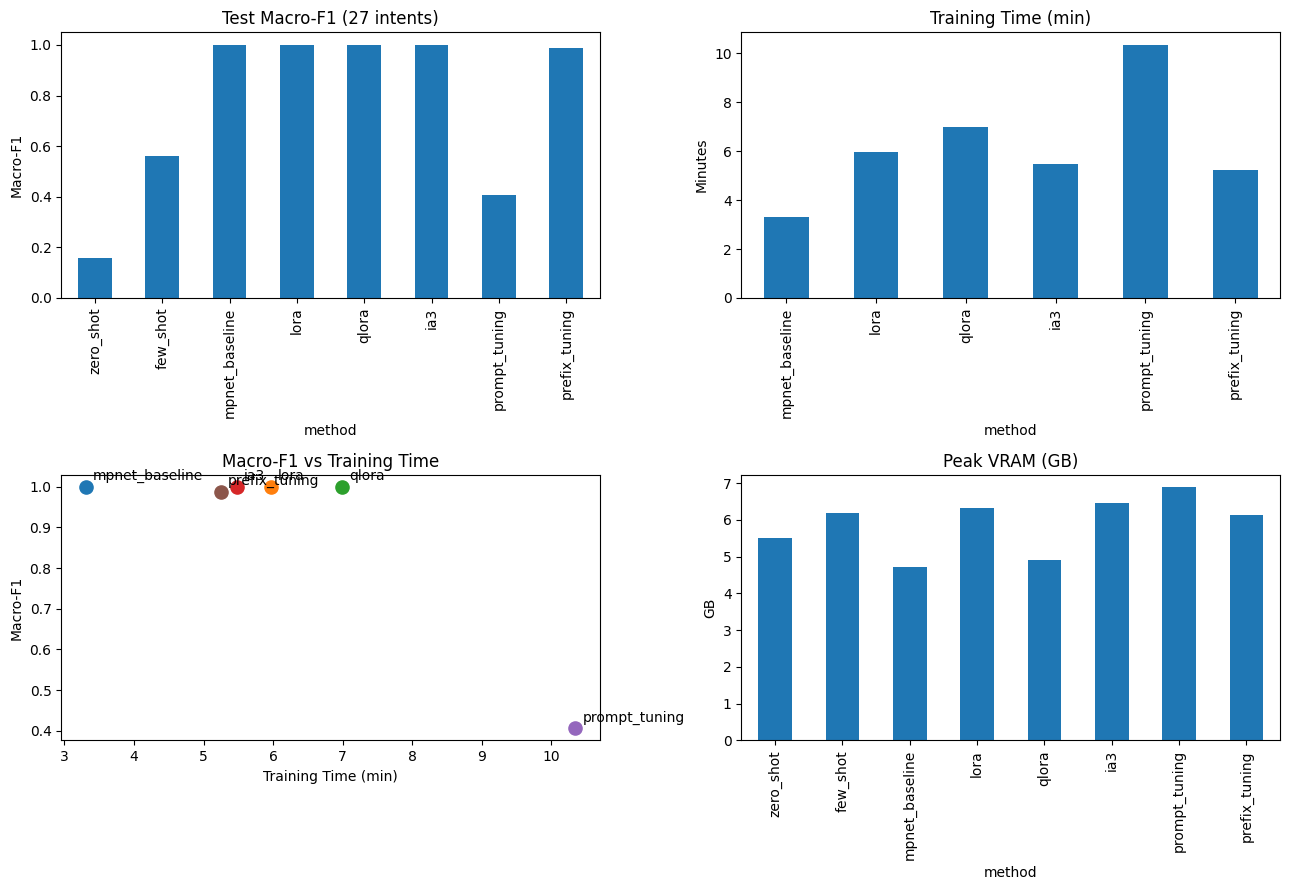

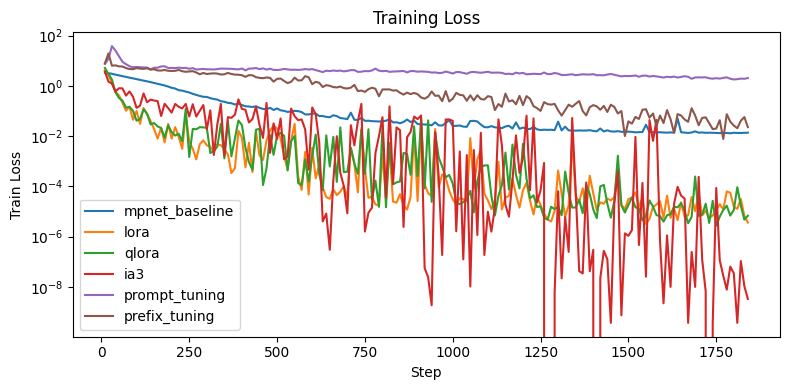

In [40]:
# ============================================================
# FINAL COMPARISON
# ============================================================

res = load_results()

order = [
    m for m in [
        "zero_shot",
        "few_shot",
        "mpnet_baseline",
        "lora",
        "qlora",
        "ia3",
        "prompt_tuning",
        "prefix_tuning"
    ]
    if m in res
]

if len(order) == 0:
    print("No results found yet.")
else:
    R = pd.DataFrame([res[m] for m in order]).set_index("method")

    cols = [
        "trainable_pct",
        "train_time_min",
        "time_per_epoch_min",
        "peak_vram_gb",
        "accuracy",
        "macro_f1",
        "category_accuracy",
        "ms_per_sample",
        "adapter_size_mb"
    ]

    # Only keep columns that actually exist
    cols = [c for c in cols if c in R.columns]

    table = R[cols].round(4)

    display(table)

    table.to_csv(
        OUT / ("comparison_smoke.csv" if SMOKE_TEST else "comparison.csv")
    )

    # --------------------------------------------------------
    # Plot 1: Macro-F1
    # --------------------------------------------------------

    fig, ax = plt.subplots(2, 2, figsize=(13, 9))

    R["macro_f1"].plot(
        kind="bar",
        ax=ax[0, 0],
        title="Test Macro-F1 (27 intents)"
    )

    ax[0, 0].set_ylim(0, 1.05)
    ax[0, 0].set_ylabel("Macro-F1")

    # --------------------------------------------------------
    # Plot 2: Training time
    # --------------------------------------------------------

    T = R[R["train_time_min"] > 0]

    if not T.empty:

        T["train_time_min"].plot(
            kind="bar",
            ax=ax[0, 1],
            title="Training Time (min)"
        )

        ax[0, 1].set_ylabel("Minutes")

    else:

        ax[0, 1].text(
            0.5,
            0.5,
            "No training results yet",
            ha="center",
            va="center",
            transform=ax[0, 1].transAxes
        )

        ax[0, 1].set_title("Training Time (min)")
        ax[0, 1].set_xticks([])

    # --------------------------------------------------------
    # Plot 3: Accuracy vs training time
    # --------------------------------------------------------

    if not T.empty:

        for m, row in T.iterrows():

            ax[1, 0].scatter(
                row["train_time_min"],
                row["macro_f1"],
                s=90
            )

            ax[1, 0].annotate(
                m,
                (
                    row["train_time_min"],
                    row["macro_f1"]
                ),
                textcoords="offset points",
                xytext=(5, 5)
            )

        ax[1, 0].set_title("Macro-F1 vs Training Time")
        ax[1, 0].set_xlabel("Training Time (min)")
        ax[1, 0].set_ylabel("Macro-F1")

    else:

        ax[1, 0].text(
            0.5,
            0.5,
            "No training results yet",
            ha="center",
            va="center",
            transform=ax[1, 0].transAxes
        )

        ax[1, 0].set_xticks([])
        ax[1, 0].set_yticks([])

    # --------------------------------------------------------
    # Plot 4: Peak VRAM
    # --------------------------------------------------------

    if "peak_vram_gb" in R.columns:

        R["peak_vram_gb"].plot(
            kind="bar",
            ax=ax[1, 1],
            title="Peak VRAM (GB)"
        )

        ax[1, 1].set_ylabel("GB")

    plt.tight_layout()

    plt.savefig(
        OUT / "comparison.png",
        dpi=150
    )

    plt.show()

    # --------------------------------------------------------
    # Training loss curves
    # --------------------------------------------------------

    plt.figure(figsize=(8, 4))

    plotted = False

    for m in order:

        h = res[m].get("loss_history", [])

        if h:

            plt.plot(
                [s for s, _ in h],
                [l for _, l in h],
                label=m
            )

            plotted = True

    if plotted:

        plt.yscale("log")
        plt.xlabel("Step")
        plt.ylabel("Train Loss")
        plt.legend()
        plt.title("Training Loss")

    else:

        plt.text(
            0.5,
            0.5,
            "No training loss data yet",
            ha="center",
            va="center",
            transform=plt.gca().transAxes
        )

        plt.xticks([])
        plt.yticks([])

    plt.tight_layout()

    plt.savefig(
        OUT / "loss_curves.png",
        dpi=150
    )

    plt.show()

## 10. Conclusions and limitations

Fill this section only after the final (SMOKE_TEST=False) run. Report the real accuracy, macro-F1, training time, trainable-parameter percentage, VRAM, and saved-model size from `results.json` and `comparison.csv`.

Important: the smoke run is only a pipeline check. Do not present smoke-test metrics as the final experiment.
